In [121]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

orders = pd.read_csv("olist_orders_dataset.csv")
order_items = pd.read_csv("olist_order_items_dataset.csv")
order_reviews = pd.read_csv("olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")
payments = pd.read_csv("olist_order_payments_dataset.csv")


orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)


# 1 Línea: pedidos por mes `plt.plot`

* Cargar orders y convertir order_purchase_timestamp a datetime.
* Filtrar order_status == 'delivered' (opcional).
* Crear columna de mes con .dt.to_period('M').
* groupby por mes y contar order_id con nunique.
* Recortar meses extremos (2016 y sept–oct 2018 casi no tienen datos): buena * lección de "mira tus datos antes de graficar".
* Graficar mes vs. número de pedidos; título, etiquetas y rotar ticks.

,order_purchase_timestamp,order_id,month
40643,2018-03-27 18:57:23,78c9d1353276b2af75baeb1e1fd400f7,2018-03
14678,2017-08-28 21:57:49,7c9956750739a47dba7a6928ba2f0245,2017-08
94766,2017-02-03 21:54:21,721e8bafa01037b2af767f8de9617d97,2017-02
6097,2017-03-16 12:39:35,949042a6b24b4ba4b1376ee35f46e56c,2017-03
25352,2017-07-23 11:22:00,0bea543455029a72056bd0e781a8dca7,2017-07


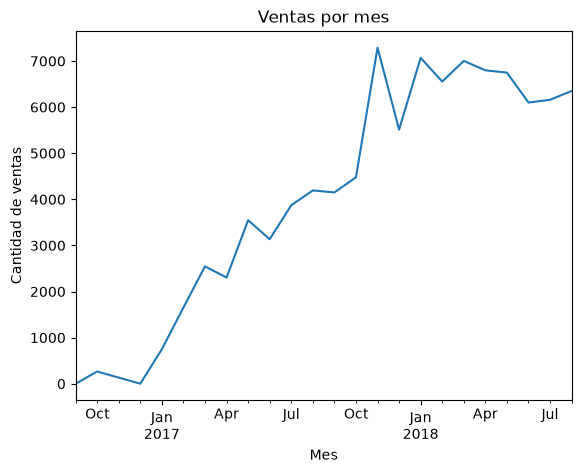

In [122]:
# solo ventas entregadas
df1 = orders[orders["order_status"] == "delivered"]

# para evitar saturar la memoria y la vista, corto sólo las columnas que necesito
df1 = df1[["order_purchase_timestamp", "order_id"]]

# Crear una columna mes a partir de "order_purchase_timestamp"
df1["month"] = df1["order_purchase_timestamp"].dt.to_period("M")

# utilizo sample(5) para mostrar 5 elementos aleatorias del dataframe
display(df1.sample(5))

# Agrupar por mes y contar order_id
resultado = df1.groupby("month")["order_id"].nunique()
# ahora va el plot, fecha vs valor numérico equivale a un line plot
resultado.plot(
    kind = "line",
    title = "Ventas por mes",
    xlabel= "Mes",
    ylabel = "Cantidad de ventas"
)
plt.show()

# 2 Barras horizontales: top 10 categorías por ingreso `plt.barh`
* Merge order_items + products por product_id.
* groupby categoría → suma de price.
* Tomar las 10 mayores con .nlargest(10).
* Invertir el orden para que la mayor quede arriba y graficar con barh.

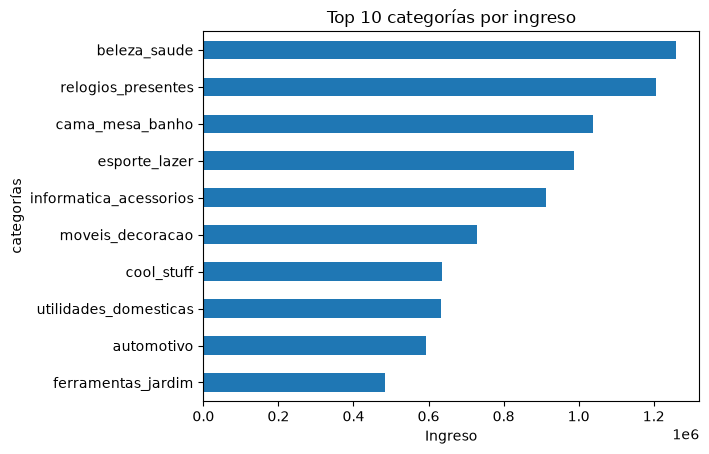

In [123]:
df2_order_items = order_items[["price", "product_id"]]
df2_products = products[["product_id", "product_category_name"]]
df2 = df2_products.merge(df2_order_items, on = "product_id", how = "left")
resultado = df2.groupby("product_category_name")["price"].sum().nlargest(10).sort_values(ascending = True)
panel2 = resultado.plot(
    kind = "barh",
    title = "Top 10 categorías por ingreso",
    xlabel = "Ingreso",
    ylabel = "categorías"
)

# 3 Histograma: distribución del precio `plt.hist`
* Usar order_items['price'].
* Primer histograma directo: se verá muy sesgado.
* Repetir con bins en escala log o con np.log10(price).
* Discusión: por qué la media engaña. Marcar media y mediana con axvline.

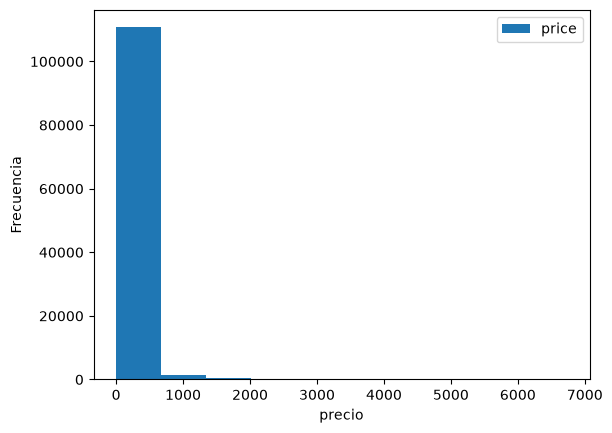

In [124]:
df3 = order_items[["price"]]
df3.plot(
    kind = "hist",
    xlabel = "precio",
    ylabel = "Frecuencia"
)
plt.show()

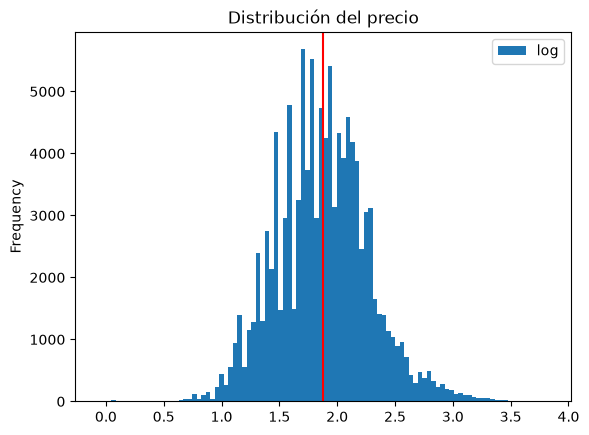

In [125]:
import numpy as np
fig, ax = plt.subplots()

df3 = order_items[["price"]]
df3["log"] = df3["price"].apply(np.log10)
df3["log"].plot(
    kind = "hist",
    title = "Distribución del precio",
    bins = 100
)

media = df3["log"].mean()
mediana = df3["log"].median()
# Como la media y la mediana son iguales, solo será una linea.
plt.axvline(media, color = "red")
plt.legend()
plt.show()

# 4 Histograma comparativo: días de entrega reales vs. estimados `hist + alpha`
* En orders, convertir a datetime las columnas de compra, entrega real y entrega estimada.
* Calcular dias_reales = entregado − compra y dias_estimados = estimado − compra (en .dt.days).
* Eliminar NaN (pedidos no entregados).
* Dos histogramas en el mismo eje con alpha=0.5 y leyenda.

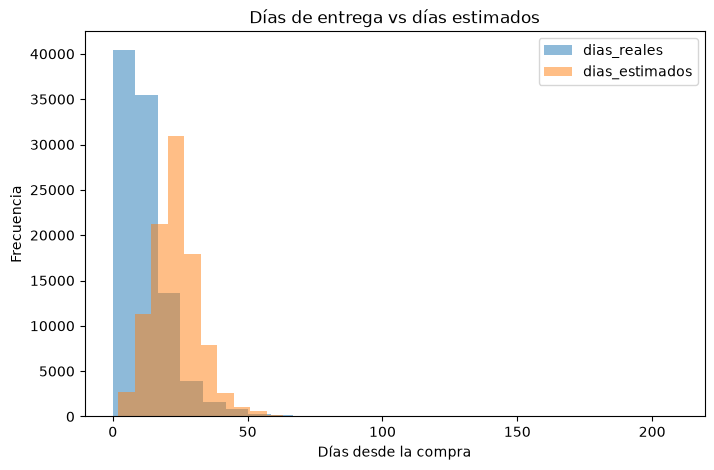

In [126]:
import matplotlib .pyplot as plt
lienzo, pintura = plt.subplots(figsize = (8,5))

df4 = orders[["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]]
df4["dias_reales"] = (df4["order_delivered_customer_date"] - df4["order_purchase_timestamp"]).dt.days
df4["dias_estimados"] = (df4["order_estimated_delivery_date"] - df4["order_purchase_timestamp"]).dt.days

df4 = df4.dropna(subset = ["order_delivered_customer_date"])
df4.isna().sum()

df4["dias_reales"].plot(
    kind = "hist",
    alpha = 0.5,
    ax = pintura,
    bins = 25
)

df4["dias_estimados"].plot(
    kind = "hist",
    alpha = 0.5,
    ax = pintura,
    title = "Días de entrega vs días estimados",
    bins = 25
)

plt.xlabel("Días desde la compra")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

# 5 Boxplot: calificación vs. días de retraso `plt.boxplot`

1. En orders, calcular retraso = entregado − estimado en días.
2. Merge con order_reviews por order_id (quitar duplicados por order_id: hay pedidos con más de una reseña).
3. Agrupar el retraso por review_score (1–5) → lista de 5 arrays.
4. Pasar la lista a boxplot con etiquetas 1–5.
5. Conclusión esperada: las calificaciones de 1 tienen retrasos mucho mayores.

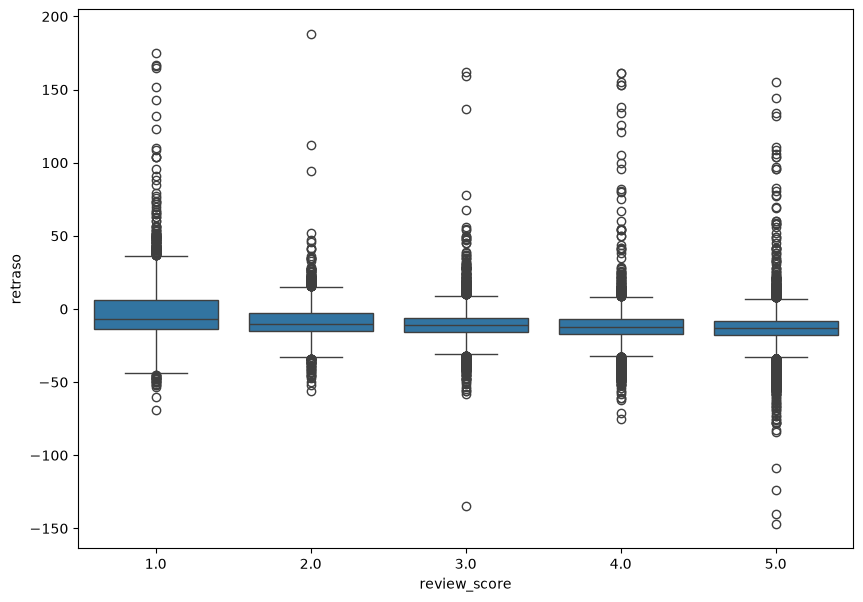

In [127]:
df5 = orders[["order_id", "order_delivered_customer_date", "order_estimated_delivery_date"]]

df5["retraso"] = (df5["order_delivered_customer_date"] - df5["order_estimated_delivery_date"]).dt.days

orders5 = df5[["order_id", "retraso"]]
reviews5 = order_reviews[["order_id", "review_score"]].drop_duplicates(subset="order_id")

merge5 = orders5.merge(reviews5, on = "order_id", how = "left")
merge5 = merge5.dropna()

lienzo, pintura = plt.subplots(figsize = (10,7))
sns.boxplot(data = merge5, x = "review_score", y = "retraso")
plt.show()

# 6 Barras con error: calificación promedio a tiempo vs. tarde `{plt.bar(yerr=)`
1. Usar el mismo merge de la gráfica 5.
2. Crear columna booleana tarde = retraso > 0.
3. groupby('tarde') → mean y std de review_score.
4. Graficar barras con yerr=std.

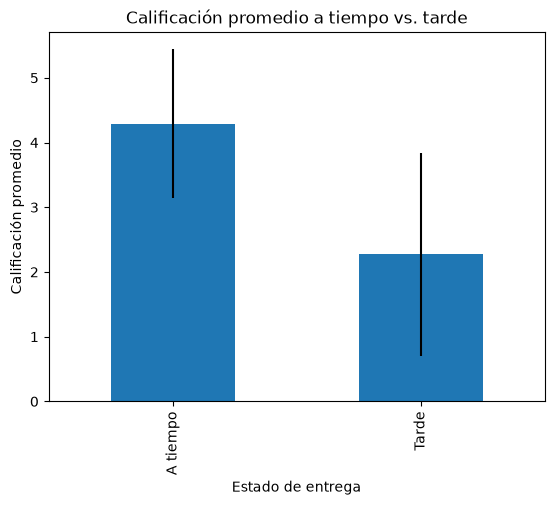

In [128]:
df6 =merge5
df6["tarde"] = df6["retraso"] > 0

df6["clasificacion"] = df6["tarde"].apply(
    lambda x: "A tiempo" if x == False else "Tarde"
)

df6 = merge5.groupby("clasificacion")["review_score"].agg(["mean", "std"])
df6

lienzo, pintura = plt.subplots()
df6["mean"].plot(
    kind = "bar",
    yerr = df6["std"],
    title = "Calificación promedio a tiempo vs. tarde",
    xlabel = "Estado de entrega",
    ylabel = "Calificación promedio"
)
plt.show()

# 7 Pastel / dona: métodos de pago `plt.pie`
1. order_payments → value_counts() de payment_type.
2. Agrupar not_defined y categorías pequeñas en "otros".
3. Graficar con autopct='%1.1f%%'; para dona, wedgeprops={'width':0.4}.
4. Discusión: por qué los pasteles suelen ser mala idea; comparar con la versión en barras.

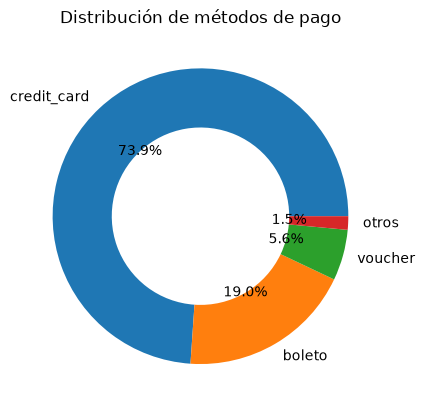

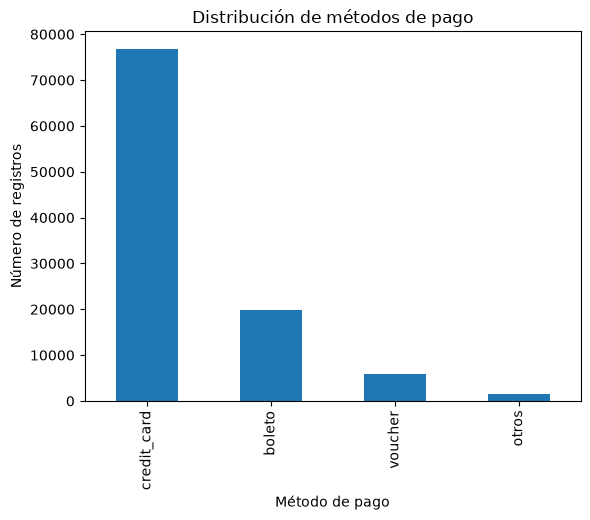

In [129]:
fig, ax = plt.subplots()
df7 = payments
df7["payment_type"].value_counts()

def agrupar(x):
    if x in ["not_defined", "debit_card"]:
        return "otros"
    else:
        return x

df7["payment_type"] = df7["payment_type"].apply(agrupar)

df7["payment_type"].value_counts().plot(
    kind= "pie",
    autopct= "%1.1f%%",
    wedgeprops={'width':0.4},
    title = "Distribución de métodos de pago"
)

fig, ax = plt.subplots()
df7["payment_type"].value_counts().plot(
    kind = "bar",
    title = "Distribución de métodos de pago",
    xlabel = "Método de pago",
    ylabel = "Número de registros"
)

plt.show()

# 8 Barras agrupadas: monto promedio por mensualidades y método de pago `pivot + bar`
1. Tomar order_payments.
2. Crear rangos de payment_installments con pd.cut: 1, 2–3, 4–6, 7–10, más de 10.
3. pivot_table: index = rango, columns = payment_type, values = payment_value, aggfunc = 'mean'.
4. Barras agrupadas desplazando cada serie con x + i*ancho (o df.plot(kind='bar')).

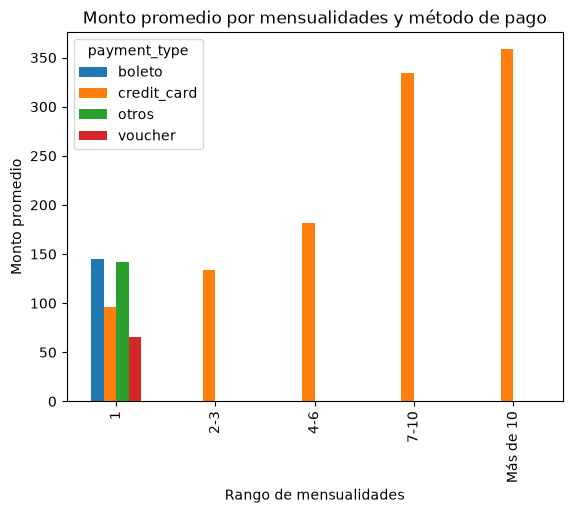

In [130]:
df8 = payments
df8["rango_mens"] = pd.cut(
    df8["payment_installments"],
    bins=[0, 1, 3, 6, 10, np.inf],
    labels=["1", "2-3", "4-6", "7-10", "Más de 10"]
)

pivot = df8.pivot_table( 
    index = "rango_mens",
    columns = "payment_type",
    values = "payment_value",
    aggfunc = "mean"
)

pivot.plot(
    kind = "bar",
    title = "Monto promedio por mensualidades y método de pago",
    xlabel = "Rango de mensualidades",
    ylabel = "Monto promedio"
)
plt.show()

# 9 Barras apiladas: estado del pedido por estado de la república `pivot + bottom=`
1. Merge orders + customers por customer_id.
2. pivot_table: index = customer_state, columns = order_status, values = order_id, aggfunc = 'count', fill_value=0.
3. Normalizar por fila (dividir entre .sum(axis=1)) para tener porcentajes.
4. Quedarse con los 10 estados con más pedidos.
5. Apilar barras con un loop acumulando bottom.

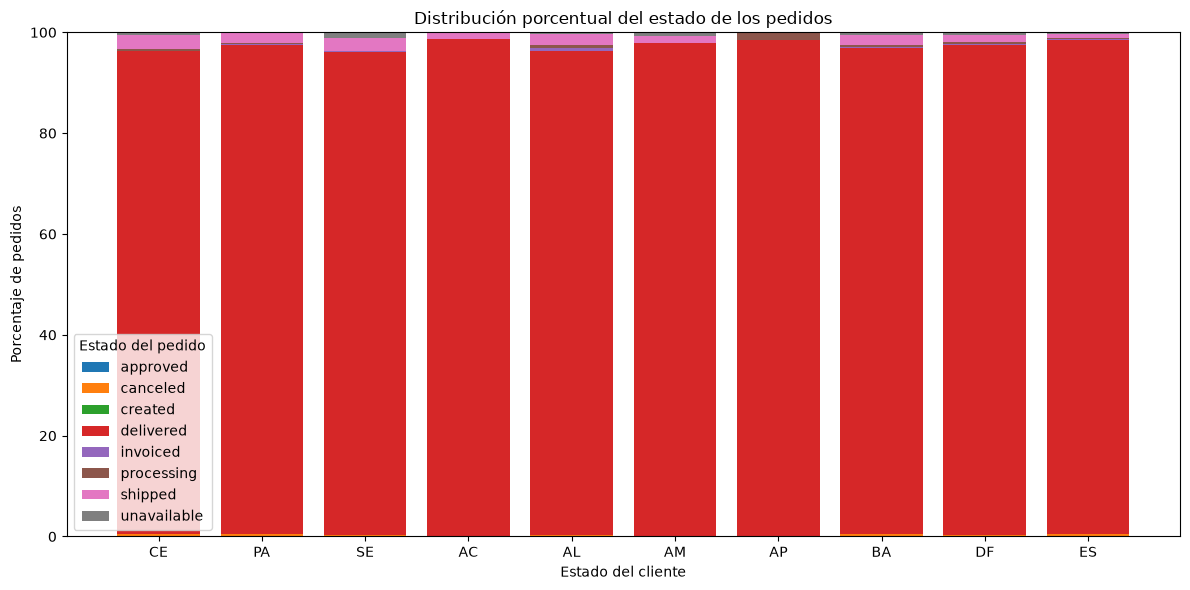

In [132]:
df9 = orders.merge(customers, on = "customer_id", how = "left")

df9 = df9[["customer_state", "customer_id", "order_status", "order_id"]]

pivot9 = df9.pivot_table(
    index = "customer_state",
    columns = "order_status",
    values = "order_id",
    aggfunc= "count",
    fill_value = 0
)

def porcentaje(fila):
    total = fila.sum()
    if total == 0:
        return fila * 0
    else:
        return (fila/total) * 100

porcentajes = pivot9.apply(porcentaje, axis = 1)

top9 = porcentajes.sum(axis=1).nlargest(10).index
porcentajes = porcentajes.loc[top9]

fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(porcentajes))

for estado_pedido in porcentajes.columns:
    valores = porcentajes[estado_pedido].values

    ax.bar(
        porcentajes.index,
        valores,
        bottom=bottom,
        label=estado_pedido
    )

    bottom += valores

ax.set_title("Distribución porcentual del estado de los pedidos")
ax.set_xlabel("Estado del cliente")
ax.set_ylabel("Porcentaje de pedidos")
ax.legend(title='Estado del pedido')
plt.tight_layout()
plt.show()

# 10 Dispersión: peso del producto vs. costo de envío `plt.scatter`
* Merge order_items + products por product_id.
* Tomar product_weight_g y freight_value; quitar NaN.
* Muestrear con .sample(3000) (110k puntos saturan la gráfica).
* Graficar con alpha bajo; opcionalmente ejes en escala log.
* Extra: colorear por price con c= y agregar plt.colorbar().

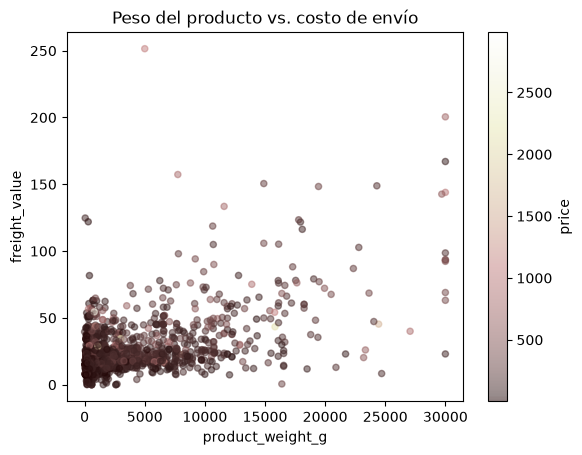

In [ ]:
df10 = order_items.merge(products, on = "product_id", how = "left")
df10 = df10.dropna(how= "all")
df10 = df10.sample(3000)
df10[["product_weight_g", "freight_value", "price"]].plot(
    kind = "scatter",
    x = "product_weight_g",
    y = "freight_value",
    alpha = 0.5,
    c = "price",
    title = "Peso del producto vs. costo de envío",
    colormap = "pink"
)
plt.show()

# 11 Mapa de calor: pedidos por día de la semana × hora `pivot + imshow`
pivot + imshow
* De order_purchase_timestamp extraer .dt.dayofweek y .dt.hour.
* pivot_table: index = día, columns = hora, values = order_id, aggfunc = 'count'.
* plt.imshow(pivot, aspect='auto', cmap='YlOrRd').
* Etiquetas Lun–Dom en y, 0–23 en x; agregar colorbar.
* Extra: escribir valores en las celdas con doble loop de ax.text.

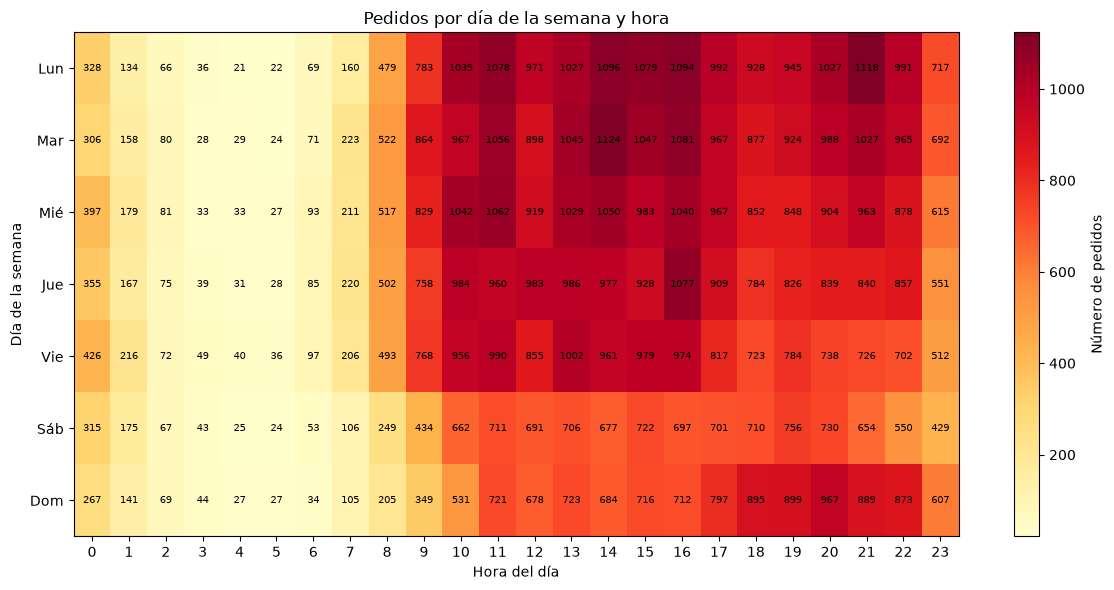

In [ ]:
df11 = orders
df11["dia"] = orders["order_purchase_timestamp"].dt.dayofweek
df11["hora"] = orders["order_purchase_timestamp"].dt.hour

fig, ax = plt.subplots(figsize = (12,6))

pivot = df11.pivot_table(
    index = "dia",
    columns = "hora",
    values = "order_id",
    aggfunc= "count"
)

panel11 = plt.imshow(pivot,
    aspect = "auto",
    cmap = "YlOrRd",
)

pintura.set_ylabel("Lun-Dom")
pintura.set_xlabel("0-23")


ax.set_yticks(range(7))
ax.set_yticklabels([
    'Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'
])

ax.set_xticks(range(24))
ax.set_xticklabels(range(24))

ax.set_title('Pedidos por día de la semana y hora')
ax.set_xlabel('Hora del día')
ax.set_ylabel('Día de la semana')

fig.colorbar(panel11, ax=ax, label='Número de pedidos')
plt.tight_layout()

for i in range(7):
    for j in range(24):
        ax.text(j, i, pivot.iloc[i, j],
                ha='center', va='center', fontsize=7)

plt.show()

# Dashboard final: subplots + doble eje `plt.subplots + twinx`
1. Reutilizar los dataframes de las gráficas 1, 2, 5 y 11.
2. fig, axes = plt.subplots(2, 2, figsize=(14,10)).
3. Panel 1: pedidos por mes y, con twinx(), ingreso mensual en el segundo eje (merge orders + order_items, groupby mes, suma de price).
4. Demás paneles: top categorías, boxplot de reseñas y heatmap.
5. fig.suptitle, plt.tight_layout() y savefig('dashboard.png', dpi=150).

In [ ]:
# Número de pedidos por mes
df1 = orders[orders["order_status"] == "delivered"]

df1 = df1[["order_purchase_timestamp", "order_id"]]

df1["month"] = df1["order_purchase_timestamp"].dt.to_period("M")

numero_pedidos = df1.groupby("month")["order_id"].nunique()


In [ ]:
# Para calcular el ingreso mensual
df12_items = orders.merge(order_items, on = "order_id", how = "left")
df12_items = df12_items[df12_items["order_status"] == "delivered"]
df12_items["mes"] = df12_items["order_purchase_timestamp"].dt.to_period("M")

ingreso_mensual = df12_items.groupby("mes")["price"].sum()

In [ ]:
# Combinar las dos series
resumen_mensual = pd.concat(
    [
        numero_pedidos.rename('pedidos'),
        ingreso_mensual.rename('ingresos')
    ],
    axis=1
).loc['2017-01':'2018-08'].dropna()

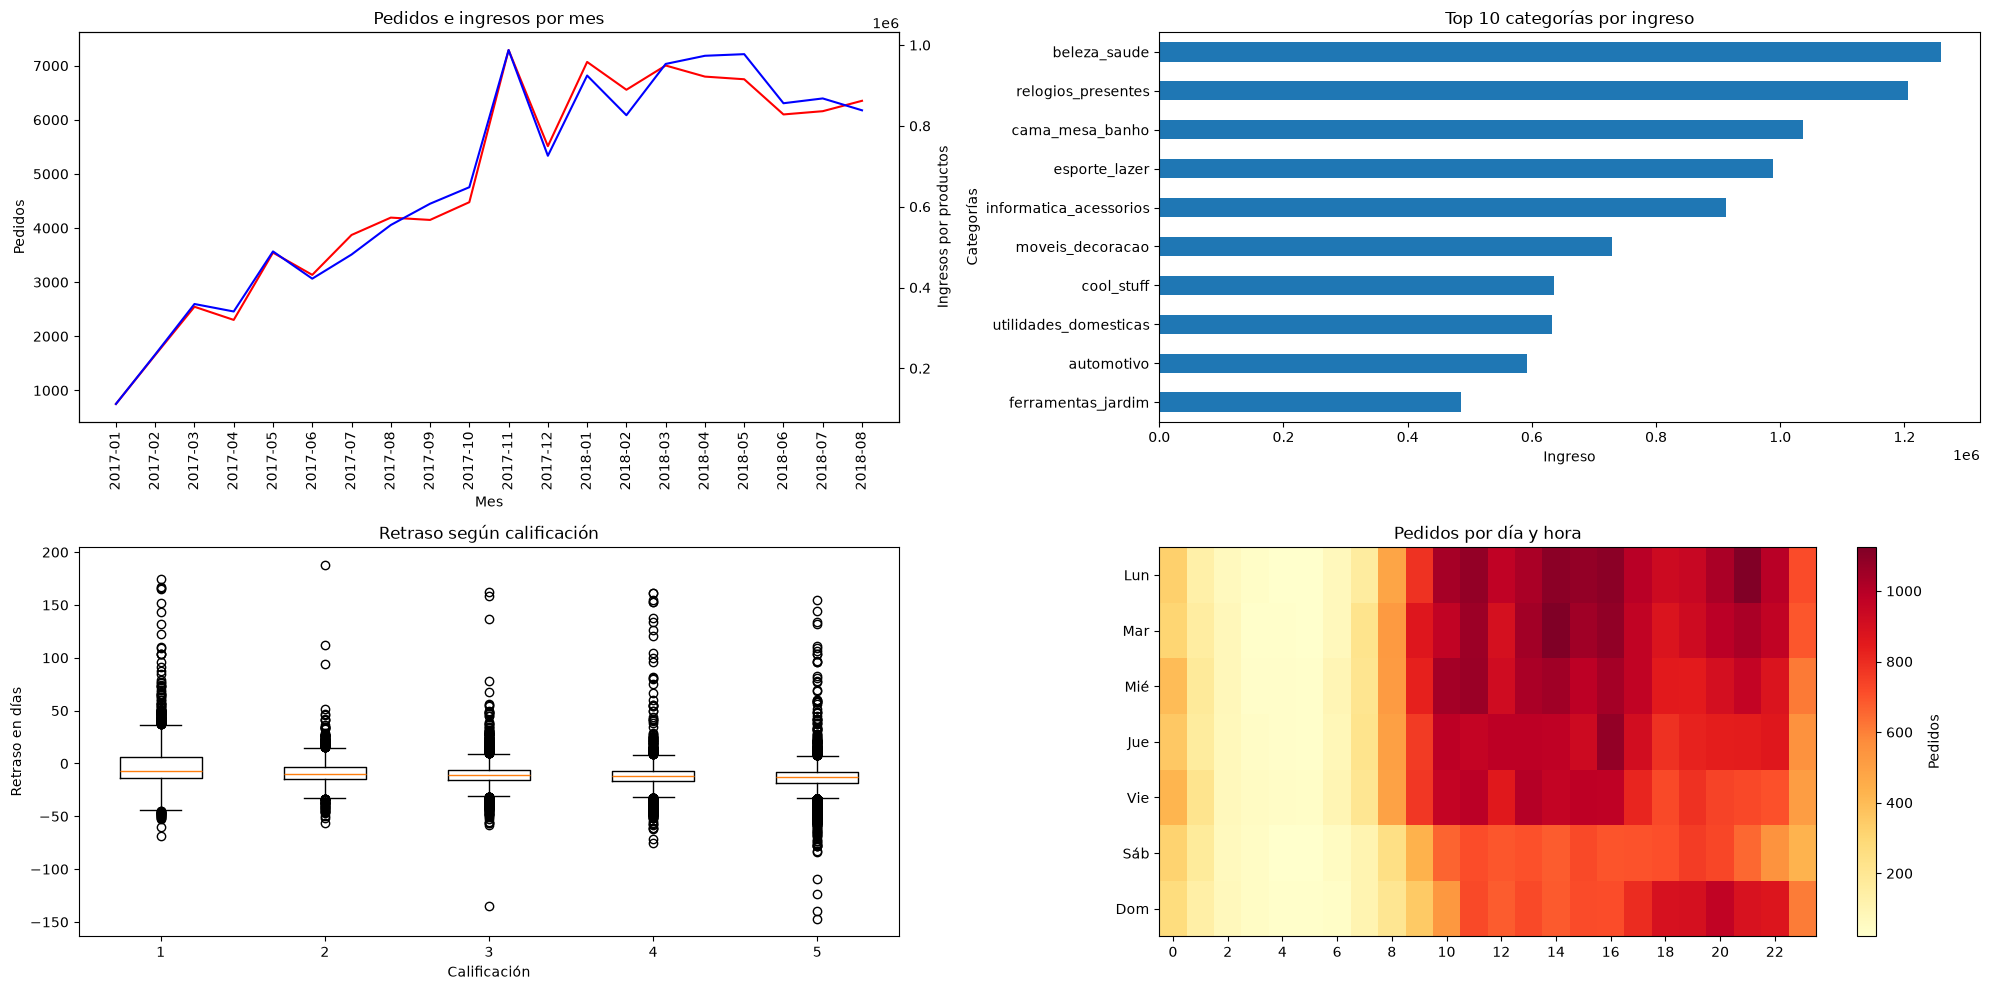

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20,10))

# Primer panel: pedidos e ingresos por mes
ax1 = axes[0, 0]

ax1.plot(
    resumen_mensual.index.astype(str),
    resumen_mensual['pedidos'],
    color = "red"
)
ax1.set_title('Pedidos e ingresos por mes')
ax1.set_xlabel('Mes')
ax1.set_ylabel('Pedidos')
ax1.tick_params(axis='x', rotation=90)

# Segundo eje vertical para ingresos
ax1b = ax1.twinx()
ax1b.plot(
    resumen_mensual.index.astype(str),
    resumen_mensual['ingresos'],
    color = "blue"
)
ax1b.set_ylabel('Ingresos por productos')


# Panel 2: top categorías
panel2 = resultado.plot(
    kind = "barh",
    title = "Top 10 categorías por ingreso",
    xlabel = "Ingreso",
    ylabel = "Categorías",
    ax = axes[0,1]
)

# Panel 3: retraso por calificación
ax3 = axes[1,0]
ax3.boxplot(box5)
ax3.set_title('Retraso según calificación')
ax3.set_xlabel('Calificación')
ax3.set_ylabel('Retraso en días')


# Panel 4:mapa de calor
ax4 = axes[1,1]
panel11 = axes[1,1].imshow(pivot,
    aspect = "auto",
    cmap = "YlOrRd",
)
ax4.set_title('Pedidos por día y hora')
ax4.set_yticks(range(7))
ax4.set_yticklabels([
    'Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'
])
ax4.set_xticks(range(0, 24, 2))
ax4.set_xticklabels(range(0, 24, 2))
fig.colorbar(imagen, ax=ax4, label='Pedidos')


plt.tight_layout()
plt.show()

import warnings
warnings.filterwarnings('ignore')